# One source, two images

This activity uses a deliberately simple, synthetic point-mass lens. Image and source positions are measured in units of the Einstein angle, so the lens equation is

$$\beta=\theta-\frac{1}{\theta}.$$

For a nonzero source offset, the equation has two image positions, one on each side of the lens. The second panel shows the total point-source magnification as the source approaches alignment. These curves illustrate the lens equation; they are not a model of a galaxy, observed data, or a telescope image.

## Try it

- Change `SOURCE_OFFSET` and compare the two image positions.
- Which image is farther from the lens? Does that change as the source moves?
- What happens to the ideal point-source magnification near perfect alignment?
- Which assumptions would fail first for an extended galaxy lens or source?

The model is a useful place to start because every curve follows from one equation. Real strong lenses bring mass profiles, extended light, and instrumental blurring into the same image.

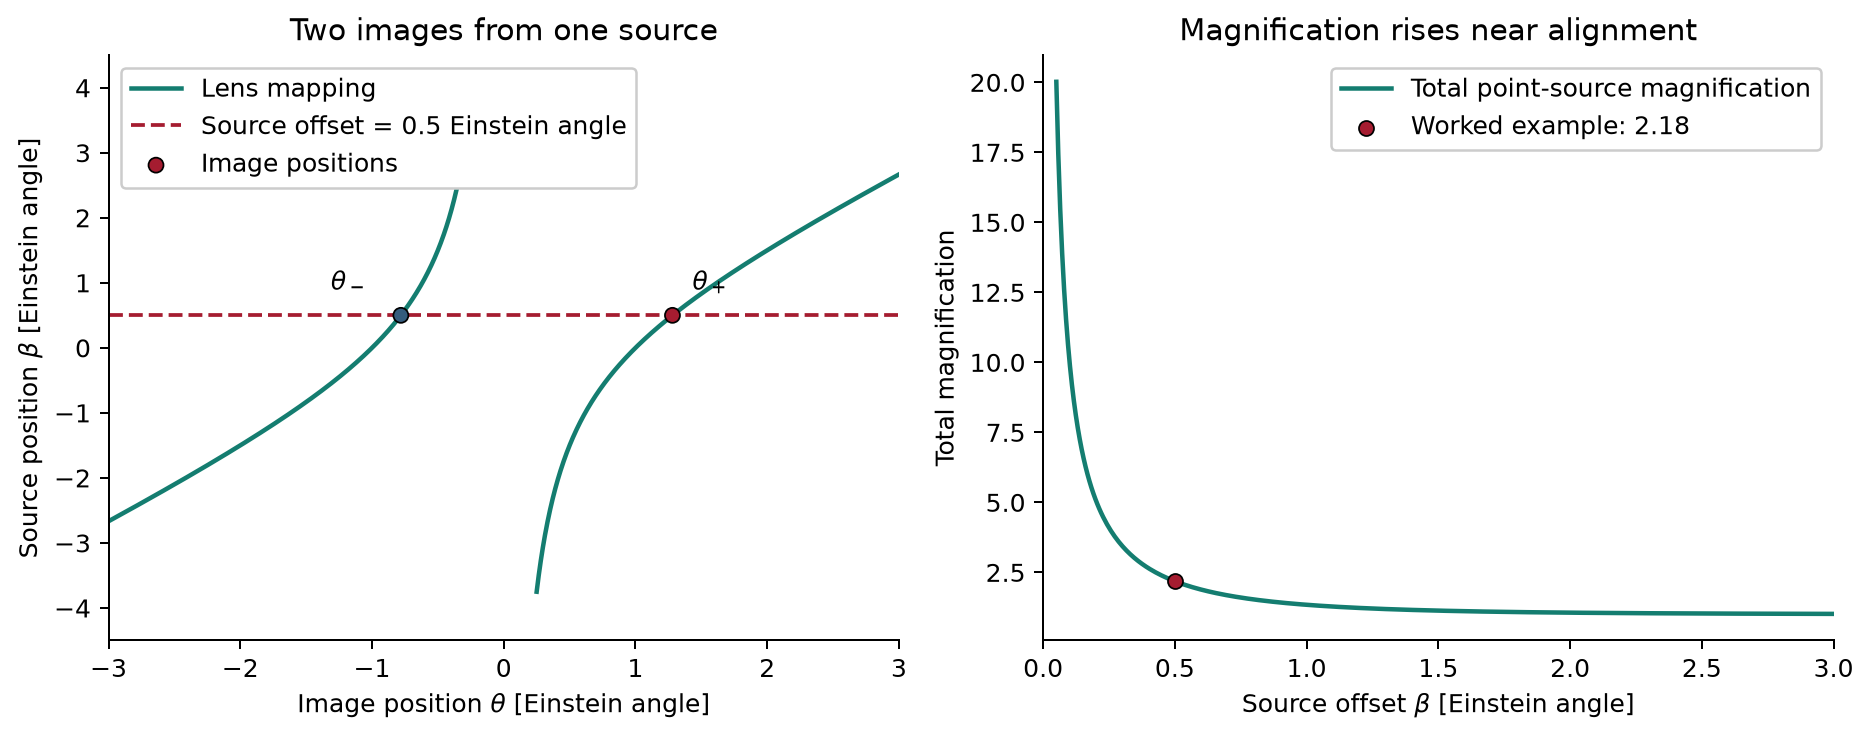

In [6]:
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from tdpy.verbosity import print

SOURCE_OFFSET = 0.5  # [Einstein angle]


def point_lens_images(source_offset):
    discriminant = np.sqrt(source_offset**2 + 4.0)
    return 0.5 * (source_offset + discriminant), 0.5 * (source_offset - discriminant)


def total_magnification(source_offset):
    return (source_offset**2 + 2.0) / (source_offset * np.sqrt(source_offset**2 + 4.0))


theta_positive, theta_negative = point_lens_images(SOURCE_OFFSET)
image_positions = np.array([theta_positive, theta_negative])
recovered_offsets = image_positions - 1.0 / image_positions
if not np.allclose(recovered_offsets, SOURCE_OFFSET):
    raise RuntimeError("Image positions do not satisfy the normalized lens equation")

negative_theta = np.linspace(-3.0, -0.25, 700)
positive_theta = np.linspace(0.25, 3.0, 700)
figure, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), facecolor="white")
axes[0].plot(negative_theta, negative_theta - 1.0 / negative_theta,
             color="#147D70", linewidth=1.8, label="Lens mapping")
axes[0].plot(positive_theta, positive_theta - 1.0 / positive_theta,
             color="#147D70", linewidth=1.8)
axes[0].axhline(SOURCE_OFFSET, color="#A51C30", linestyle="--", linewidth=1.5,
                label=f"Source offset = {SOURCE_OFFSET:g} Einstein angle")
axes[0].scatter(image_positions, np.full(2, SOURCE_OFFSET), color=("#A51C30", "#355C7D"),
                edgecolor="black", linewidth=0.7, zorder=4, label="Image positions")
axes[0].annotate(r"$\theta_+$", (theta_positive, SOURCE_OFFSET), xytext=(8, 10),
                 textcoords="offset points", fontsize=10)
axes[0].annotate(r"$\theta_-$", (theta_negative, SOURCE_OFFSET), xytext=(-28, 10),
                 textcoords="offset points", fontsize=10)
axes[0].set(xlabel=r"Image position $\theta$ [Einstein angle]",
            ylabel=r"Source position $\beta$ [Einstein angle]",
            title="Two images from one source", xlim=(-3, 3), ylim=(-4.5, 4.5))
axes[0].legend(loc="upper left", fancybox=True, framealpha=1.0, facecolor="white")

source_offsets = np.linspace(0.05, 3.0, 400)
magnifications = total_magnification(source_offsets)
axes[1].plot(source_offsets, magnifications, color="#147D70", linewidth=1.8,
             label="Total point-source magnification")
axes[1].scatter([SOURCE_OFFSET], [total_magnification(SOURCE_OFFSET)], color="#A51C30",
                edgecolor="black", linewidth=0.7, zorder=4,
                label=f"Worked example: {total_magnification(SOURCE_OFFSET):.2f}")
axes[1].set(xlabel=r"Source offset $\beta$ [Einstein angle]",
            ylabel="Total magnification", title="Magnification rises near alignment",
            xlim=(0, 3))
axes[1].legend(loc="upper right", fancybox=True, framealpha=1.0, facecolor="white")
for axis in axes:
    axis.grid(False)
    axis.spines[["top", "right"]].set_visible(False)
    axis.tick_params(colors="black")
    axis.xaxis.label.set_color("black")
    axis.yaxis.label.set_color("black")
    axis.title.set_color("black")
figure.tight_layout()

current_directory = Path.cwd().resolve()
repository_root = next(
    candidate for candidate in (current_directory, *current_directory.parents)
    if candidate.name == "gravitational-imaging-teaching-team"
)
figure_path = repository_root / "examples" / "visuals" / (
    "point_mass_lensing_activity_"
    + datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
    + ".png"
)
figure_path.parent.mkdir(parents=True, exist_ok=True)
print(f"Writing to {figure_path.relative_to(repository_root).as_posix()}...")
figure.savefig(figure_path, dpi=300, bbox_inches="tight", facecolor="white")
buffer = BytesIO()
figure.savefig(buffer, format="png", dpi=180, bbox_inches="tight", facecolor="white")
display(Image(data=buffer.getvalue(), alt="Point-mass lens mapping with two image positions for a source offset of half an Einstein angle, alongside total magnification as the source approaches alignment."))
plt.close(figure)